In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

In [53]:
sales = pd.read_csv(
    "../data/raw/ecommerce_sales_customer_analytics_150k.csv"
)

In [54]:
sales.head()

,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,...,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,...,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,...,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,...,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44,True,6
3,ORD-567636,2023-01-21,07:20:26,Completed,Social Media,CUST-023928,Jennifer Smith,65,Male,Consumer,...,53.34,34.39,20.85,546.52,277.84,247.83,45.35,5638.30,True,7
4,ORD-820028,2022-05-13,09:46:21,Completed,Social Media,CUST-012730,Jessica Wang,34,Female,Consumer,...,133.63,421.35,23.03,2785.27,1231.88,1530.36,54.94,13240.10,True,8


In [55]:
sales.shape

(138116, 46)

In [56]:
sales.columns.tolist()

['order_id',
 'order_date',
 'order_time',
 'order_status',
 'sales_channel',
 'customer_id',
 'customer_name',
 'customer_age',
 'gender',
 'customer_segment',
 'customer_type',
 'customer_city',
 'customer_state',
 'customer_country',
 'region',
 'customer_postal_code',
 'payment_method',
 'payment_status',
 'currency',
 'shipping_method',
 'warehouse',
 'delivery_days',
 'estimated_delivery_days',
 'delivery_status',
 'return_status',
 'return_reason',
 'customer_rating',
 'review_sentiment',
 'customer_review',
 'marketing_channel',
 'campaign_name',
 'coupon_code',
 'loyalty_points_earned',
 'loyalty_points_redeemed',
 'quantity',
 'gross_sales',
 'discount_amount',
 'tax_amount',
 'shipping_cost',
 'net_sales',
 'product_cost',
 'profit',
 'profit_margin_percentage',
 'customer_lifetime_value',
 'is_repeat_customer',
 'customer_order_count']

In [57]:
sales["order_date"] = pd.to_datetime(
    sales["order_date"]
)

In [58]:
sales["order_date"].min(), sales["order_date"].max()

(Timestamp('2021-01-01 00:00:00'), Timestamp('2025-12-31 00:00:00'))

In [59]:
observation_date = sales["order_date"].max()

In [60]:
observation_date = pd.Timestamp("2025-06-30")

In [61]:
historical_data = sales[
    sales["order_date"] <= observation_date
].copy()

In [62]:
future_data = sales[
    (sales["order_date"] > observation_date) &
    (sales["order_date"] <= observation_date + pd.Timedelta(days=90))
].copy()

In [63]:
print("quantity" in sales.columns)

True


In [64]:
print("net_sales" in sales.columns)

True


In [65]:
customer_features = historical_data.groupby(
    "customer_id"
).agg(
    Last_Purchase_Date=("order_date", "max"),
    First_Purchase_Date=("order_date", "min"),
    Order_Count=("order_id", "nunique"),
    Total_Spending=("net_sales", "sum"),
    Total_Quantity=("quantity", "sum")
).reset_index()

In [66]:
customer_features["Recency_Days"] = (
    observation_date -
    customer_features["Last_Purchase_Date"]
).dt.days

In [67]:
customer_features["Customer_Lifetime_Days"] = (
    customer_features["Last_Purchase_Date"] -
    customer_features["First_Purchase_Date"]
).dt.days

In [68]:
customer_features["Average_Order_Value"] = (
    customer_features["Total_Spending"] /
    customer_features["Order_Count"].replace(0, np.nan)
)

In [69]:
customer_features["Purchase_Frequency"] = (
    customer_features["Order_Count"] /
    customer_features["Customer_Lifetime_Days"].replace(0, np.nan)
).fillna(0)

In [70]:
customer_features[
    [
        "customer_id",
        "Recency_Days",
        "Order_Count",
        "Total_Spending",
        "Total_Quantity",
        "Average_Order_Value",
        "Customer_Lifetime_Days",
        "Purchase_Frequency"
    ]
].head()

,customer_id,Recency_Days,Order_Count,Total_Spending,Total_Quantity,Average_Order_Value,Customer_Lifetime_Days,Purchase_Frequency
0,CUST-000001,40,7,6629.92,30,947.131429,1562,0.004481
1,CUST-000002,98,10,18138.96,54,1813.896000,1427,0.007008
2,CUST-000003,25,7,7798.59,27,1114.084286,1476,0.004743
3,CUST-000004,45,6,8880.93,45,1480.155000,378,0.015873
4,CUST-000005,228,8,10063.97,70,1257.996250,1249,0.006405


In [71]:
customer_features["Purchase_Frequency"] = (
    customer_features["Purchase_Frequency"]
    .fillna(0)
)

In [72]:
sales.columns.tolist()

['order_id',
 'order_date',
 'order_time',
 'order_status',
 'sales_channel',
 'customer_id',
 'customer_name',
 'customer_age',
 'gender',
 'customer_segment',
 'customer_type',
 'customer_city',
 'customer_state',
 'customer_country',
 'region',
 'customer_postal_code',
 'payment_method',
 'payment_status',
 'currency',
 'shipping_method',
 'warehouse',
 'delivery_days',
 'estimated_delivery_days',
 'delivery_status',
 'return_status',
 'return_reason',
 'customer_rating',
 'review_sentiment',
 'customer_review',
 'marketing_channel',
 'campaign_name',
 'coupon_code',
 'loyalty_points_earned',
 'loyalty_points_redeemed',
 'quantity',
 'gross_sales',
 'discount_amount',
 'tax_amount',
 'shipping_cost',
 'net_sales',
 'product_cost',
 'profit',
 'profit_margin_percentage',
 'customer_lifetime_value',
 'is_repeat_customer',
 'customer_order_count']

In [73]:
[col for col in sales.columns if any(
    word in col.lower()
    for word in ["sales", "amount", "price", "revenue", "total", "spend"]
)]

['sales_channel', 'gross_sales', 'discount_amount', 'tax_amount', 'net_sales']

In [86]:
# Re-create the derived customer features

customer_features["Recency_Days"] = (
    observation_date -
    customer_features["Last_Purchase_Date"]
).dt.days

customer_features["Customer_Lifetime_Days"] = (
    customer_features["Last_Purchase_Date"] -
    customer_features["First_Purchase_Date"]
).dt.days

customer_features["Average_Order_Value"] = (
    customer_features["Total_Spending"] /
    customer_features["Order_Count"].replace(0, np.nan)
)

customer_features["Purchase_Frequency"] = (
    customer_features["Order_Count"] /
    customer_features["Customer_Lifetime_Days"].replace(0, np.nan)
).fillna(0)

In [87]:
customer_features.columns.tolist()

['customer_id',
 'Last_Purchase_Date',
 'First_Purchase_Date',
 'Order_Count',
 'Total_Spending',
 'Total_Quantity',
 'Future_90_Day_Spend',
 'Recency_Days',
 'Customer_Lifetime_Days',
 'Average_Order_Value',
 'Purchase_Frequency']

In [91]:
future_spending = future_data.groupby(
    "customer_id"
).agg(
    Future_90_Day_Spend=("net_sales", "sum")
).reset_index()

customer_features = customer_features.merge(
    future_spending,
    on="customer_id",
    how="left"
)

customer_features["Future_90_Day_Spend"] = (
    customer_features["Future_90_Day_Spend"]
    .fillna(0)
)

In [92]:
customer_features.columns.tolist()

['customer_id',
 'Last_Purchase_Date',
 'First_Purchase_Date',
 'Order_Count',
 'Total_Spending',
 'Total_Quantity',
 'Future_90_Day_Spend_x',
 'Recency_Days',
 'Customer_Lifetime_Days',
 'Average_Order_Value',
 'Purchase_Frequency',
 'Future_90_Day_Spend_y',
 'Future_90_Day_Spend']

In [93]:
customer_features["Future_90_Day_Spend"].describe()

count    24818.000000
mean       338.554697
std        904.317918
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max      11935.380000
Name: Future_90_Day_Spend, dtype: float64

In [94]:
print(
    "Customers with future purchases:",
    (customer_features["Future_90_Day_Spend"] > 0).sum()
)

print(
    "Customers without future purchases:",
    (customer_features["Future_90_Day_Spend"] == 0).sum()
)

Customers with future purchases: 5729
Customers without future purchases: 19089


In [95]:
future_purchase_rate = (
    (customer_features["Future_90_Day_Spend"] > 0).mean() * 100
)

print(
    f"Future purchase rate: {future_purchase_rate:.2f}%"
)

Future purchase rate: 23.08%


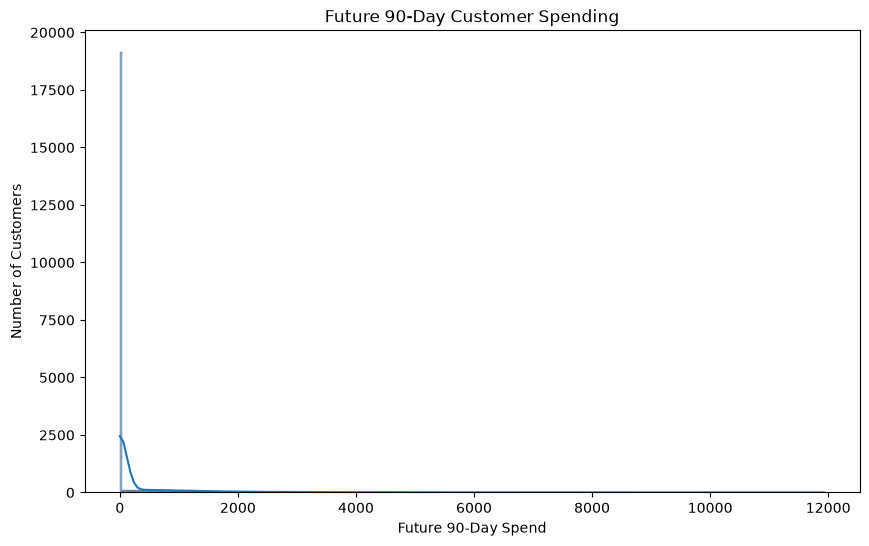

In [96]:
plt.figure(figsize=(10, 6))

sns.histplot(
    customer_features["Future_90_Day_Spend"],
    kde=True
)

plt.title("Future 90-Day Customer Spending")
plt.xlabel("Future 90-Day Spend")
plt.ylabel("Number of Customers")
plt.show()

In [97]:
clv_features = [
    "Recency_Days",
    "Order_Count",
    "Total_Spending",
    "Total_Quantity",
    "Average_Order_Value",
    "Customer_Lifetime_Days",
    "Purchase_Frequency"
]

clv_target = "Future_90_Day_Spend"

X = customer_features[clv_features].copy()
y = customer_features[clv_target].copy()

In [98]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (24818, 7)
y shape: (24818,)


In [99]:
print("Missing values in X:")
print(X.isnull().sum())

Missing values in X:
Recency_Days              0
Order_Count               0
Total_Spending            0
Total_Quantity            0
Average_Order_Value       0
Customer_Lifetime_Days    0
Purchase_Frequency        0
dtype: int64


In [100]:
print("Missing values in y:")
print(y.isnull().sum())

Missing values in y:
0


In [101]:
print("Infinite values in X:")
print(np.isinf(X).sum())

Infinite values in X:
Recency_Days              0
Order_Count               0
Total_Spending            0
Total_Quantity            0
Average_Order_Value       0
Customer_Lifetime_Days    0
Purchase_Frequency        0
dtype: int64


In [102]:
X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

In [103]:
X = X.fillna(X.median())

In [104]:
from sklearn.model_selection import train_test_split

In [105]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [106]:
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 19854
Testing samples: 4964


In [107]:
print("Training target mean:", y_train.mean())
print("Testing target mean:", y_test.mean())

Training target mean: 335.6740631610758
Testing target mean: 350.0760717163578


In [109]:
%pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
  Obtaining dependency information for xgboost from https://files.pythonhosted.org/packages/2f/3c/925394671f6a1668e2a71886de66e80be694eaf37f615cec74eefaf43107/xgboost-3.4.1-py3-none-win_amd64.whl.metadata
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.1/48.9 MB 1.3 MB/s eta 0:00:37
   ---------------------------------------- 0.3/48.9 MB 2.3 MB/s eta 0:00:22
   ---------------------------------------- 0.5/48.9 MB 3.3 MB/s eta 0:00:15
    --------------------------------------- 1.0/48.9 MB 5.4 MB/s eta 0:00:09
   - -------------------------------------- 1.6/48.9 MB 6.2 MB/s eta 0:00:08
   - -------------------------------------- 2.1/48.9 MB 7.3 MB/s eta 0:00:07
   -- ------------------------------------- 2.7/48.9 MB 8.1 MB/s eta 0:00:06
   -- --------------------------------


[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [110]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from xgboost import XGBRegressor

In [111]:
linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ 0.01,-3.35, 0.01,...,-0.03, 0.01,65.16]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['Recency_Days','Order_Count','Total_Spending',...,'Average_Order_Value', 'Customer_Lifetime_Days','Purchase_Frequency']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,380.8
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


In [112]:
linear_pred = linear_model.predict(X_test)

In [113]:
linear_mae = mean_absolute_error(
    y_test,
    linear_pred
)

linear_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        linear_pred
    )
)

linear_r2 = r2_score(
    y_test,
    linear_pred
)

In [114]:
print("Linear Regression")
print("-----------------")
print("MAE :", linear_mae)
print("RMSE:", linear_rmse)
print("R²  :", linear_r2)

Linear Regression
-----------------
MAE : 538.9969531359362
RMSE: 902.2896809751717
R²  : -0.0006452273273021003


In [115]:
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

In [116]:
rf_model.fit(
    X_train,
    y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [117]:
rf_pred = rf_model.predict(X_test)

In [118]:
rf_mae = mean_absolute_error(
    y_test,
    rf_pred
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_pred
    )
)

rf_r2 = r2_score(
    y_test,
    rf_pred
)

In [119]:
print("Random Forest")
print("-------------")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R²  :", rf_r2)

Random Forest
-------------
MAE : 540.7407649099347
RMSE: 903.3967163626803
R²  : -0.0031021527678440908


In [120]:
xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

In [121]:
xgb_model.fit(
    X_train,
    y_train
)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [122]:
xgb_pred = xgb_model.predict(X_test)

In [123]:
xgb_mae = mean_absolute_error(
    y_test,
    xgb_pred
)

xgb_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        xgb_pred
    )
)

xgb_r2 = r2_score(
    y_test,
    xgb_pred
)

In [124]:
print("XGBoost Regressor")
print("-----------------")
print("MAE :", xgb_mae)
print("RMSE:", xgb_rmse)
print("R²  :", xgb_r2)

XGBoost Regressor
-----------------
MAE : 544.7817046254837
RMSE: 915.1651840663409
R²  : -0.029407022485283374


In [125]:
clv_results = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "MAE": linear_mae,
        "RMSE": linear_rmse,
        "R2": linear_r2
    },
    {
        "Model": "Random Forest",
        "MAE": rf_mae,
        "RMSE": rf_rmse,
        "R2": rf_r2
    },
    {
        "Model": "XGBoost",
        "MAE": xgb_mae,
        "RMSE": xgb_rmse,
        "R2": xgb_r2
    }
])

In [126]:
clv_results = clv_results.sort_values(
    "RMSE"
).reset_index(drop=True)

clv_results

,Model,MAE,RMSE,R2
0,Linear Regression,538.996953,902.289681,-0.000645
1,Random Forest,540.740765,903.396716,-0.003102
2,XGBoost,544.781705,915.165184,-0.029407


In [127]:
customer_predictions = customer_features[
    ["customer_id"] + clv_features
].copy()

In [128]:
customer_predictions["Predicted_90_Day_Value"] = (
    xgb_model.predict(
        customer_predictions[clv_features]
    )
)

In [129]:
customer_predictions["Predicted_90_Day_Value"] = (
    customer_predictions["Predicted_90_Day_Value"]
    .clip(lower=0)
)

In [130]:
top_customers = customer_predictions.sort_values(
    "Predicted_90_Day_Value",
    ascending=False
)

In [131]:
top_customers.head(20)

,customer_id,Recency_Days,Order_Count,Total_Spending,Total_Quantity,Average_Order_Value,Customer_Lifetime_Days,Purchase_Frequency,Predicted_90_Day_Value
12773,CUST-012869,200,13,22197.42,81,1707.493846,1402,0.009272,6017.793457
5641,CUST-005687,325,5,2380.66,12,476.132000,1256,0.003981,6017.547363
19800,CUST-019947,513,2,977.65,4,488.825000,5,0.400000,5433.246094
17651,CUST-017783,950,1,1290.43,4,1290.430000,0,0.000000,5044.709473
17696,CUST-017828,36,12,20815.35,78,1734.612500,1390,0.008633,4037.168457
15769,CUST-015889,944,1,2591.37,8,2591.370000,0,0.000000,3950.703125
23850,CUST-024026,9,7,9479.27,41,1354.181429,520,0.013462,3823.358887
17124,CUST-017251,65,14,25218.42,98,1801.315714,1422,0.009845,3642.543213
6822,CUST-006877,569,1,2639.60,5,2639.600000,0,0.000000,3632.221191
827,CUST-000835,67,3,3916.24,21,1305.413333,23,0.130435,3567.800781


In [132]:
top_customers[
    [
        "customer_id",
        "Recency_Days",
        "Order_Count",
        "Total_Spending",
        "Average_Order_Value",
        "Predicted_90_Day_Value"
    ]
].head(20)

,customer_id,Recency_Days,Order_Count,Total_Spending,Average_Order_Value,Predicted_90_Day_Value
12773,CUST-012869,200,13,22197.42,1707.493846,6017.793457
5641,CUST-005687,325,5,2380.66,476.132000,6017.547363
19800,CUST-019947,513,2,977.65,488.825000,5433.246094
17651,CUST-017783,950,1,1290.43,1290.430000,5044.709473
17696,CUST-017828,36,12,20815.35,1734.612500,4037.168457
15769,CUST-015889,944,1,2591.37,2591.370000,3950.703125
23850,CUST-024026,9,7,9479.27,1354.181429,3823.358887
17124,CUST-017251,65,14,25218.42,1801.315714,3642.543213
6822,CUST-006877,569,1,2639.60,2639.600000,3632.221191
827,CUST-000835,67,3,3916.24,1305.413333,3567.800781


In [133]:
pca_features = [
    "Recency_Days",
    "Order_Count",
    "Total_Spending",
    "Total_Quantity",
    "Average_Order_Value",
    "Customer_Lifetime_Days",
    "Purchase_Frequency"
]

In [134]:
X_pca_data = customer_features[
    pca_features
].copy()

In [135]:
X_pca_data = X_pca_data.replace(
    [np.inf, -np.inf],
    np.nan
)

In [136]:
X_pca_data = X_pca_data.fillna(
    X_pca_data.median()
)

In [137]:
X_pca_data.isnull().sum()

Recency_Days              0
Order_Count               0
Total_Spending            0
Total_Quantity            0
Average_Order_Value       0
Customer_Lifetime_Days    0
Purchase_Frequency        0
dtype: int64

In [138]:
from sklearn.preprocessing import StandardScaler

In [139]:
pca_scaler = StandardScaler()

X_pca_scaled = pca_scaler.fit_transform(
    X_pca_data
)

In [140]:
from sklearn.decomposition import PCA

In [141]:
pca = PCA(
    n_components=2
)

X_pca = pca.fit_transform(
    X_pca_scaled
)

In [142]:
print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

Explained variance ratio:
[0.48620272 0.19764184]


In [143]:
print(
    "Total explained variance:",
    pca.explained_variance_ratio_.sum()
)

Total explained variance: 0.6838445568554523


In [144]:
pca_loadings = pd.DataFrame(
    pca.components_.T,
    columns=["PC1", "PC2"],
    index=pca_features
)

In [145]:
pca_loadings

,PC1,PC2
Recency_Days,-0.328836,0.441100
Order_Count,0.477300,-0.096106
Total_Spending,0.475569,0.363978
Total_Quantity,0.488090,0.135604
Average_Order_Value,0.182632,0.662746
Customer_Lifetime_Days,0.405700,-0.394713
Purchase_Frequency,-0.041320,0.224266


In [146]:
print("PC1 loadings:")
print(
    pca_loadings
    .sort_values(
        "PC1",
        key=abs,
        ascending=False
    )
)

PC1 loadings:
                             PC1       PC2
Total_Quantity          0.488090  0.135604
Order_Count             0.477300 -0.096106
Total_Spending          0.475569  0.363978
Customer_Lifetime_Days  0.405700 -0.394713
Recency_Days           -0.328836  0.441100
Average_Order_Value     0.182632  0.662746
Purchase_Frequency     -0.041320  0.224266


In [147]:
print("PC2 loadings:")
print(
    pca_loadings
    .sort_values(
        "PC2",
        key=abs,
        ascending=False
    )
)

PC2 loadings:
                             PC1       PC2
Average_Order_Value     0.182632  0.662746
Recency_Days           -0.328836  0.441100
Customer_Lifetime_Days  0.405700 -0.394713
Total_Spending          0.475569  0.363978
Purchase_Frequency     -0.041320  0.224266
Total_Quantity          0.488090  0.135604
Order_Count             0.477300 -0.096106


In [148]:
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

In [149]:
pca_df["customer_id"] = (
    customer_features["customer_id"].values
)

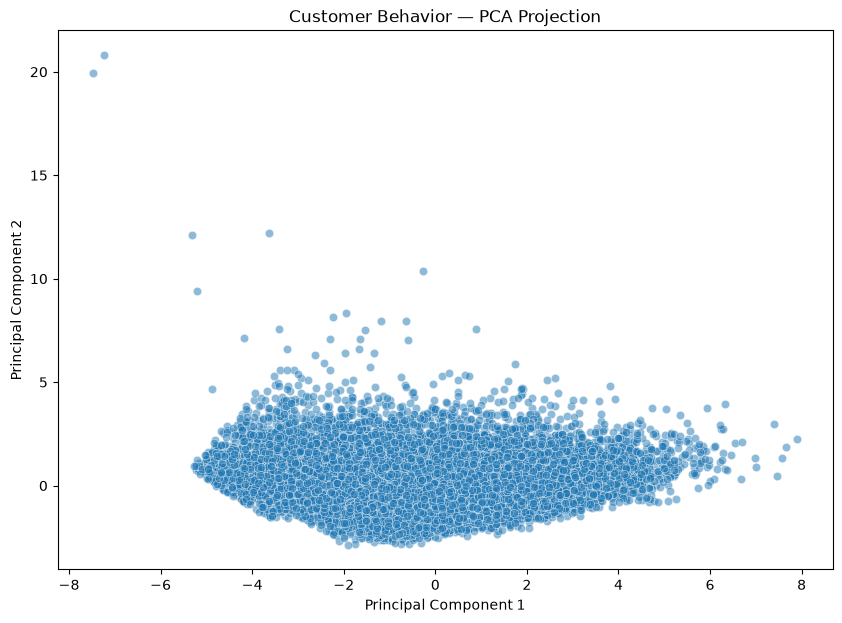

In [150]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    alpha=0.5
)

plt.title("Customer Behavior — PCA Projection")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

In [151]:
from sklearn.cluster import KMeans

In [152]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

In [153]:
customer_features["Cluster"] = (
    kmeans.fit_predict(X_pca_scaled)
)

In [154]:
pca_df["Cluster"] = (
    customer_features["Cluster"].values
)

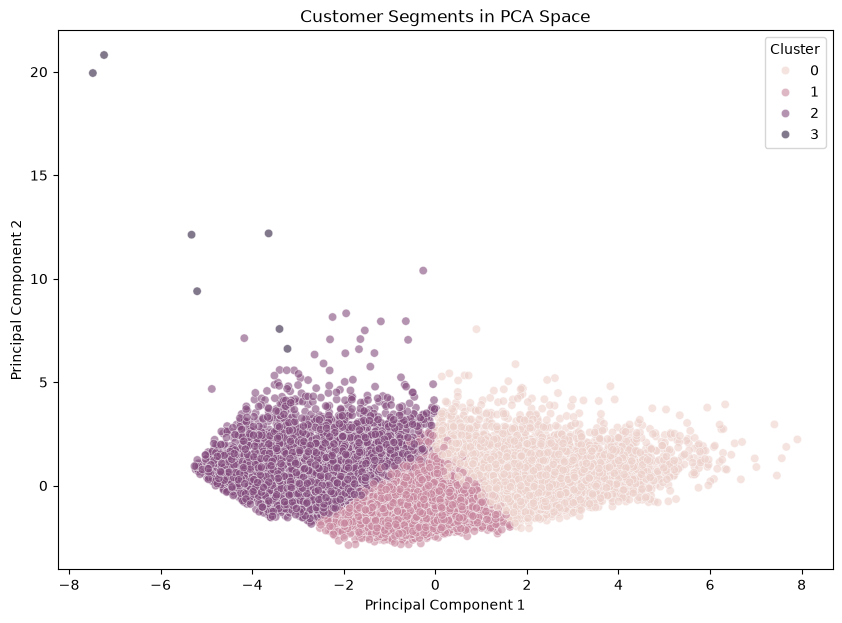

In [155]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    alpha=0.6
)

plt.title("Customer Segments in PCA Space")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

In [156]:
cluster_profile = customer_features.groupby(
    "Cluster"
)[
    [
        "Recency_Days",
        "Order_Count",
        "Total_Spending",
        "Total_Quantity",
        "Average_Order_Value",
        "Customer_Lifetime_Days",
        "Purchase_Frequency",
        "Future_90_Day_Spend"
    ]
].mean()

In [157]:
cluster_profile

,Recency_Days,Order_Count,Total_Spending,Total_Quantity,Average_Order_Value,Customer_Lifetime_Days,Purchase_Frequency,Future_90_Day_Spend
Cluster,,,,,,,,
0,205.578703,7.076635,10750.854340,43.082192,1598.628663,1209.067976,0.006068,332.611689
1,219.735682,4.574189,4814.578938,23.172773,1089.648133,1107.260121,0.004365,346.559384
2,694.798616,2.727821,3299.349688,14.668914,1220.050823,415.136622,0.008950,329.498802
3,763.857143,2.000000,3027.138571,11.000000,1513.569286,2.000000,1.190476,1120.898571


In [158]:
cluster_size = (
    customer_features["Cluster"]
    .value_counts()
    .sort_index()
)

cluster_profile["Customer_Count"] = cluster_size

cluster_profile

,Recency_Days,Order_Count,Total_Spending,Total_Quantity,Average_Order_Value,Customer_Lifetime_Days,Purchase_Frequency,Future_90_Day_Spend,Customer_Count
Cluster,,,,,,,,,
0,205.578703,7.076635,10750.854340,43.082192,1598.628663,1209.067976,0.006068,332.611689,7738
1,219.735682,4.574189,4814.578938,23.172773,1089.648133,1107.260121,0.004365,346.559384,11437
2,694.798616,2.727821,3299.349688,14.668914,1220.050823,415.136622,0.008950,329.498802,5636
3,763.857143,2.000000,3027.138571,11.000000,1513.569286,2.000000,1.190476,1120.898571,7


In [159]:
from sklearn.metrics import silhouette_score

silhouette_results = []

for k in range(2, 7):
    kmeans_test = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans_test.fit_predict(X_pca_scaled)

    score = silhouette_score(
        X_pca_scaled,
        cluster_labels
    )

    silhouette_results.append({
        "K": k,
        "Silhouette_Score": score
    })

silhouette_results = pd.DataFrame(silhouette_results)

silhouette_results

,K,Silhouette_Score
0,2,0.297453
1,3,0.263843
2,4,0.265440
3,5,0.266518
4,6,0.223273


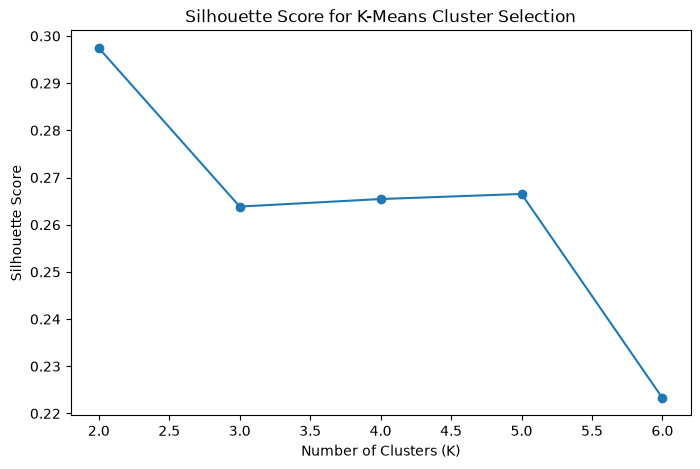

In [160]:
plt.figure(figsize=(8, 5))

plt.plot(
    silhouette_results["K"],
    silhouette_results["Silhouette_Score"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for K-Means Cluster Selection")

plt.show()

In [161]:
best_k = silhouette_results.loc[
    silhouette_results["Silhouette_Score"].idxmax(),
    "K"
]

best_score = silhouette_results["Silhouette_Score"].max()

print("Best K:", best_k)
print("Best Silhouette Score:", best_score)

Best K: 2
Best Silhouette Score: 0.2974534550001197


In [162]:
final_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

customer_features["Cluster"] = final_kmeans.fit_predict(
    X_pca_scaled
)

In [163]:
pca_df["Cluster"] = customer_features["Cluster"].values

In [164]:
final_cluster_profile = customer_features.groupby("Cluster")[
    [
        "Recency_Days",
        "Order_Count",
        "Total_Spending",
        "Total_Quantity",
        "Average_Order_Value",
        "Customer_Lifetime_Days",
        "Purchase_Frequency",
        "Future_90_Day_Spend"
    ]
].mean()

final_cluster_profile["Customer_Count"] = (
    customer_features["Cluster"]
    .value_counts()
    .sort_index()
)

final_cluster_profile

,Recency_Days,Order_Count,Total_Spending,Total_Quantity,Average_Order_Value,Customer_Lifetime_Days,Purchase_Frequency,Future_90_Day_Spend,Customer_Count
Cluster,,,,,,,,,
0,194.438480,6.461840,8998.209596,37.620720,1443.077084,1214.294400,0.005532,334.894906,12500
1,454.183796,3.384397,3603.925560,17.120393,1110.637454,745.295178,0.007023,342.268561,12318


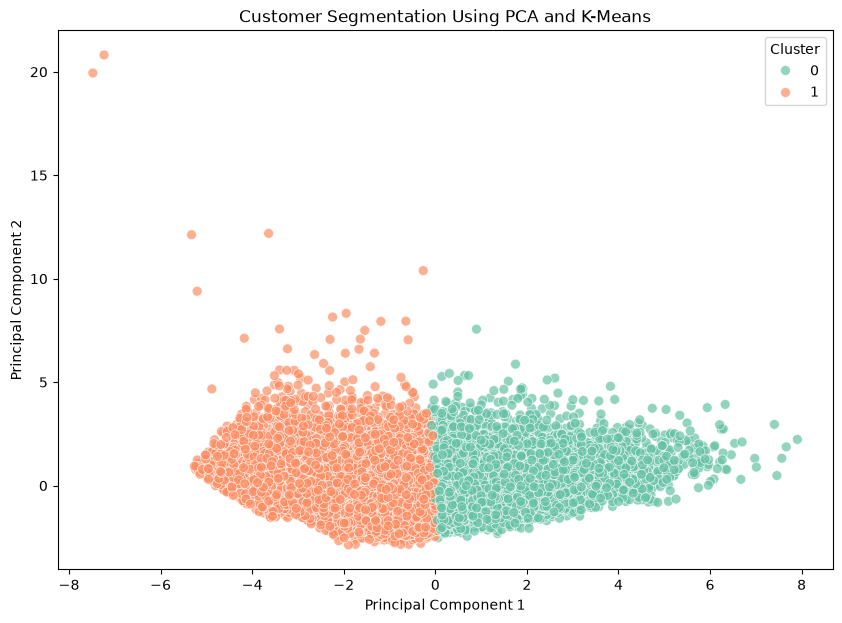

In [165]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set2",
    s=50,
    alpha=0.7
)

plt.title("Customer Segmentation Using PCA and K-Means")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")

plt.show()

In [167]:
final_cluster_summary = final_cluster_profile.copy()

final_cluster_summary = final_cluster_summary[
    [
        "Customer_Count",
        "Recency_Days",
        "Order_Count",
        "Total_Spending",
        "Total_Quantity",
        "Average_Order_Value",
        "Customer_Lifetime_Days",
        "Purchase_Frequency",
        "Future_90_Day_Spend"
    ]
]

final_cluster_summary

,Customer_Count,Recency_Days,Order_Count,Total_Spending,Total_Quantity,Average_Order_Value,Customer_Lifetime_Days,Purchase_Frequency,Future_90_Day_Spend
Cluster,,,,,,,,,
0,12500,194.438480,6.461840,8998.209596,37.620720,1443.077084,1214.294400,0.005532,334.894906
1,12318,454.183796,3.384397,3603.925560,17.120393,1110.637454,745.295178,0.007023,342.268561


In [168]:
cluster_distribution = (
    customer_features["Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Customer_Count")
)

cluster_distribution["Customer_Percentage"] = (
    cluster_distribution["Customer_Count"]
    / len(customer_features)
    * 100
)

cluster_distribution

,Customer_Count,Customer_Percentage
Cluster,,
0,12500,50.366669
1,12318,49.633331


In [169]:
cluster_names = {
    0: "Higher-Value Active Customers",
    1: "Lower-Value Less-Active Customers"
}

customer_features["Customer_Segment"] = (
    customer_features["Cluster"]
    .map(cluster_names)
)

pca_df["Customer_Segment"] = (
    pca_df["Cluster"]
    .map(cluster_names)
)

In [170]:
customer_features[
    ["customer_id", "Cluster", "Customer_Segment"]
].head(10)

,customer_id,Cluster,Customer_Segment
0,CUST-000001,0,Higher-Value Active Customers
1,CUST-000002,0,Higher-Value Active Customers
2,CUST-000003,0,Higher-Value Active Customers
3,CUST-000004,0,Higher-Value Active Customers
4,CUST-000005,0,Higher-Value Active Customers
5,CUST-000006,0,Higher-Value Active Customers
6,CUST-000007,0,Higher-Value Active Customers
7,CUST-000008,0,Higher-Value Active Customers
8,CUST-000009,1,Lower-Value Less-Active Customers
9,CUST-000010,1,Lower-Value Less-Active Customers


In [171]:
segment_comparison = final_cluster_profile.copy()

segment_comparison["Customer_Segment"] = (
    segment_comparison.index.map(cluster_names)
)

segment_comparison = segment_comparison[
    [
        "Customer_Segment",
        "Customer_Count",
        "Recency_Days",
        "Order_Count",
        "Total_Spending",
        "Total_Quantity",
        "Average_Order_Value",
        "Customer_Lifetime_Days",
        "Purchase_Frequency",
        "Future_90_Day_Spend"
    ]
]

segment_comparison

,Customer_Segment,Customer_Count,Recency_Days,Order_Count,Total_Spending,Total_Quantity,Average_Order_Value,Customer_Lifetime_Days,Purchase_Frequency,Future_90_Day_Spend
Cluster,,,,,,,,,,
0,Higher-Value Active Customers,12500,194.438480,6.461840,8998.209596,37.620720,1443.077084,1214.294400,0.005532,334.894906
1,Lower-Value Less-Active Customers,12318,454.183796,3.384397,3603.925560,17.120393,1110.637454,745.295178,0.007023,342.268561


In [172]:
spending_difference = (
    final_cluster_profile.loc[0, "Total_Spending"]
    / final_cluster_profile.loc[1, "Total_Spending"]
)

print(
    f"Cluster 0 customers spend approximately "
    f"{spending_difference:.2f}x more historically than Cluster 1."
)

Cluster 0 customers spend approximately 2.50x more historically than Cluster 1.


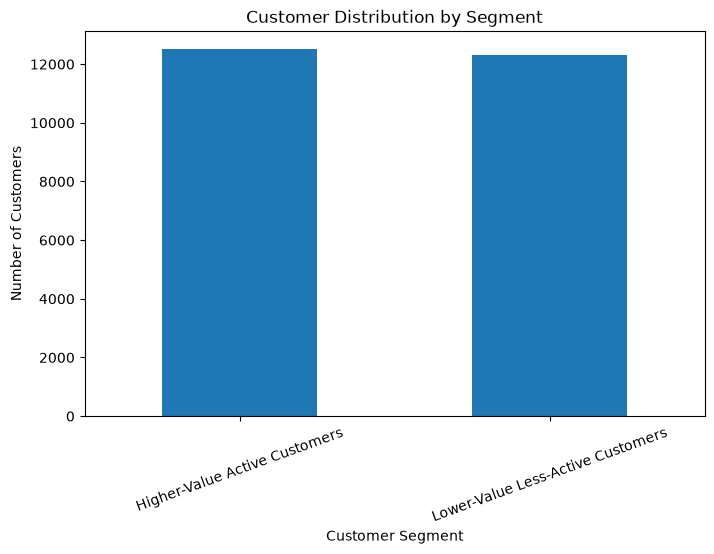

In [173]:
plt.figure(figsize=(8, 5))

segment_counts = customer_features["Customer_Segment"].value_counts()

segment_counts.plot(kind="bar")

plt.title("Customer Distribution by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)

plt.show()

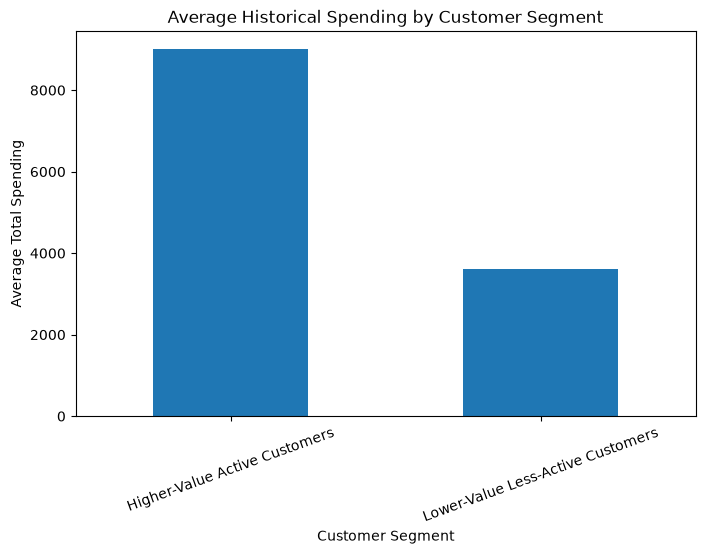

In [174]:
plt.figure(figsize=(8, 5))

segment_spending = customer_features.groupby(
    "Customer_Segment"
)["Total_Spending"].mean()

segment_spending.plot(kind="bar")

plt.title("Average Historical Spending by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Total Spending")
plt.xticks(rotation=20)

plt.show()